# Standard grating coupler: parameter optimization

[Run in Lumi Colab](https://colab.luminescentai.com/hub/user-redirect/lab/tree/tutorials/photonic_circuits/GC/GC.ipynb)

## Setup

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi

# SOI grating-coupler dimensions [um]
w_wg = 0.5
taper_length = 15.0
n_periods = 16
fill_factor = 0.5
fiber_angle = 6.9 # in clad or 10deg in air
taper_angle = 40.0
period = 0.635

# SOI dimensions [um]: 220 nm silicon with a 120 nm residual slab
h_core = 0.22
h_slab = 0.12
h_teeth = h_core - h_slab

# wavelengths [um]
wavelength = 1.55
bandwidth = 0.1
nwls = 11
wavelengths = np.linspace(wavelength - bandwidth / 2, wavelength + bandwidth / 2, nwls)

# Gaussian fiber mode dimensions [um]
D_beam = 10.4  # mode field diameter, SMF-28
Dlim = 1.5 * D_beam  # beam frame width


def setup(path, wavelength, wavelengths,n_periods, period,fill_factor, taper_length, taper_angle):
    boundaries = ["PML", ["PEC", "PML"], "PML"]
    nres = 10
    shutoff = 1e-4
    tmax = 1000  # max time [periods]
    PML_decay = [0.001, 0.1, 0.001]
    shot_every = 10

    l_wg = 2
    margin = 1.

    source_offset = .25
    zmargin = 1
    zmin =  - zmargin
    fiber_offset=zmargin+source_offset
    zmax = h_core + fiber_offset
    z_port = zmax - source_offset

    nclad = 1.444
    materials = {
        "Si": lumi.material(3.478),
        "SiO2": lumi.material(nclad),
    }
    background = "SiO2"

    WG = (1, 0)
    SLAB = (2, 0)
    BBOX = (3, 0)
    layer_stack = LayerStack(
        layers={
            "core": LayerLevel(
                layer=LogicalLayer(layer=WG),
                thickness=h_core,
                zmin=0,
                material="Si",
                mesh_order=200,
            ),
            "slab": LayerLevel(
                layer=LogicalLayer(layer=SLAB),
                thickness=h_slab,
                zmin=0,
                material="Si",
                mesh_order=100,
            ),
        }
    )

    c = gf.Component()
    gc = c << gf.components.grating_coupler_elliptical_uniform(
        n_periods=n_periods,
        period=period,
        fill_factor=fill_factor,
        taper_length=taper_length,
        taper_angle=taper_angle,
        wavelength=wavelength,
        fiber_angle=fiber_angle,
        nclad=nclad,
        layer_slab=SLAB,
        cross_section=gf.cross_section.cross_section(width=w_wg, layer=WG),
    )
    wg = c << gf.components.straight(
        length=l_wg,
        cross_section=gf.cross_section.cross_section(width=w_wg, layer=WG),
    )
    wg.connect("o2", gc.ports["o1"])
    # c << gf.components.bbox(component=c, layer=BBOX, top=margin, bottom=margin)
    x_fiber = gc.ports["o2"].x + np.sin(np.deg2rad(fiber_angle)) * fiber_offset
    c << gf.components.bbox(  # enclose fiber frame
        component=c,
        layer=BBOX,
        top=margin,
        bottom=margin,
        right=max(0, x_fiber + Dlim / 2 - gc.xmax),
    )
    full_bbox = c.bbox_np().tolist()

    clipper = gf.Component()
    clipper_ref = clipper << gf.components.rectangle(
        size=(full_bbox[1][0] - full_bbox[0][0], full_bbox[1][1]),
        layer=WG,
    )

    half_component = gf.Component()
    clipper_ref.movex(full_bbox[0][0])
    for layer in (WG, SLAB, BBOX):
        clipped = gf.boolean(
            c,
            clipper,
            operation="and",
            layer=layer,
            layer1=layer,
            layer2=WG,
        )
        half_component << clipped
    half_component.add_port("wg", port=wg.ports["o1"])
    half_component.flatten()
    c = half_component
    c.plot()

    bbox = c.bbox_np().tolist()
    bbox[0][1] = 0
    bbox[0].append(zmin)
    bbox[1].append(zmax)

# sources, monitors
    frames = [
        lumi.plane_frame(
            "wg",
            start=[-w_wg / 2 - margin, -zmargin],
            stop=[0, h_core + zmargin],
            boundaries=[("PML", "PEC"), "PML"],
            wls_mode_solver=[wavelength],
        ),
        lumi.plane_frame(
            "fiber",
            modes=[
                [
                    lumi.gaussian_mode(
                        D_beam,
                        nclad,
                        dx=wavelength / nclad / nres,
                        theta=np.deg2rad(fiber_angle),
                        wl=wavelength,
                        half="y+",
                        Dlim=Dlim,
                    )
                ]
            ],
            start=[-Dlim / 2, 0],
            stop=[Dlim / 2, Dlim / 2],
        ),
    ]

    fiber_origin = [
        gc.ports["o2"].center[0] + np.sin(np.deg2rad(fiber_angle)) * fiber_offset,
        0,
        z_port,
    ]
    fiber_basis = [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
    sources = [
        lumi.source(
            "fiber",
            fiber_origin,
            fiber_basis,
            frame="fiber",
            wl=wavelength,
            bandwidth=max(max(wavelengths) - min(wavelengths), wavelength / 8),
        )
    ]
    monitors = [
        lumi.gf_monitor("wg", c, layer_stack, frame="wg"),
        lumi.monitor("fiber", fiber_origin, fiber_basis, frame="fiber"),
    ]

    views = [lumi.view("Ey", y=0, z=h_slab+h_teeth / 2)]
    lumi.mesh(path, c, layer_stack, materials, zmin, zmax)
    lumi.setup(
        path=path,
        wl=wavelength,
        wls=wavelengths,
        materials=materials,
        background=background,
        boundaries=boundaries,
        bbox=bbox,
        frames=frames,
        sources=sources,
        monitors=monitors,
        nres=nres,
        tmax=tmax,
        shutoff=shutoff,
        PML_decay=PML_decay,
        views=views,
        shot_every=shot_every,
    )


## Optimization

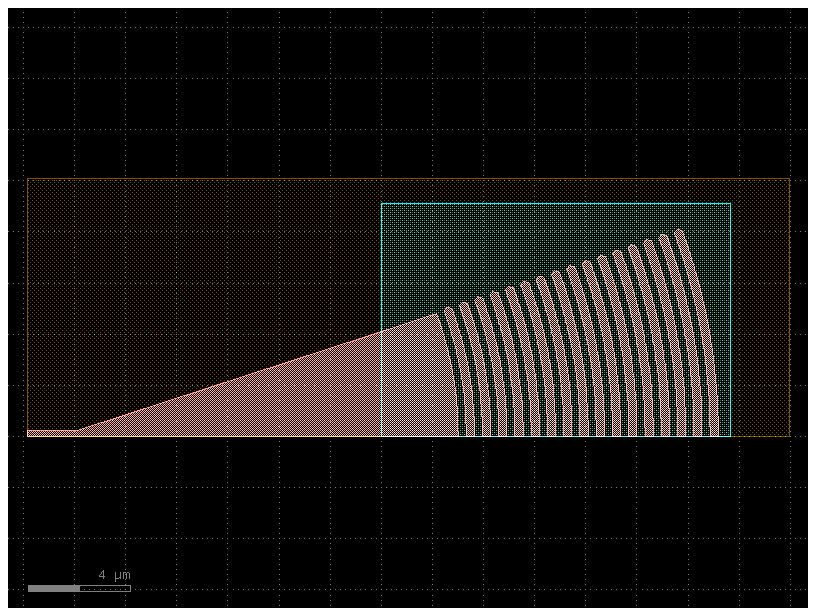

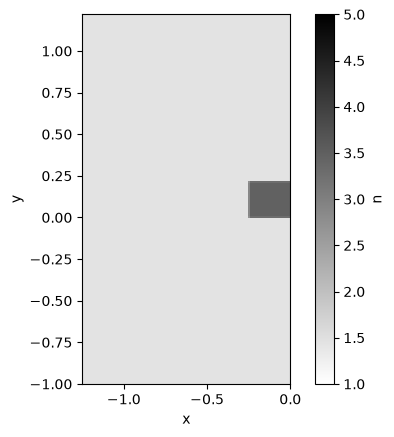

using simulation folder runs/GC
backend using simulation folder runs/GC
setting up simulation...
processing geometry bodies...
generating voxels...
voxelation: 25.126476 seconds (1.51 G allocations: 56.342 GiB, 40.97% gc time, 88.38% compilation time)
Yee mode λ=1.0: neff 2.1969
making sources fiber ...
making monitors fiber wg ...
run: runs/GC
processor: GPU
cpu threads: 48

nres: 10.0
courant: 0.9
subpixel_smoothing: 1
  
boundaries: [:PML :PML; :PEC :PML; :PML :PML]

sources
   fiber: 20.16, 0, 1.22 

monitors
   fiber: 20.16, 0, 1.22 
   wg: -1.84, 0, 0 

original size: (683, 219, 46)
padded size: (743, 231, 85)
cell count: 14,588,805

step size: 88.0 steps/period
source duration: 3.93 periods

max time: 1,000 periods
max steps: 88,000
max load: 1,283,814,840,000 cell-steps
energy decay threshold: 0.001

running simulation...
accumulating dft field...
period 10, decay: 0.144, 1.51 seconds/period, 851.35 Mcells/s
period 20, decay: 0.056, 0.156 seconds/period, 8232.91 Mcells/s
period

In [6]:
# optimized: n_periods=16, period=0.635, fill_factor=0.5, h_slab=0.12 -> efficiency 0.43 at 1.55 um
params = [n_periods, period, fill_factor, taper_length, taper_angle]
path = os.path.join("runs", "GC")
setup(path, wavelength, wavelengths, *params)
lumi.solve(path)

# parameter search loop
# params_history=[]
# efficiency_history=[]
# params=[n_periods, period, fill_factor, taper_length, taper_angle]
# efficiency=0
# goal=.4 # uniform grating coupler can reach only 0.4 efficiency at best. for better, use apodization or inverse design
# maxiter = 10
# for iter in range(maxiter):
#     path = os.path.join("runs", f"GC_opt_{iter}")
#     setup(path, wavelength, wavelengths, *params)
#     lumi.solve(path)
#     
#     sol = lumi.load(path)
#     fiber_mode = sol["monitors"]["fiber"]["modes"][0]["-"]
#     wg_mode = sol["monitors"]["wg"]["modes"][0]["+"]
#     S = np.abs(wg_mode /fiber_mode) ** 2
#     efficiency = S[nwls // 2]
#
#     params_history.append(params.copy())
#     efficiency_history.append(efficiency)
#     print(f'{iter}: params={params}, efficiency={efficiency:.4f}')
#
#     # todo for reader: use a black-box optimizer to update params
#     break
#
#     if efficiency > goal:
#         break


## Results

loading solution from runs/GC
may take a minute if simulation folder is remotely mounted
params=[16, 0.635, 0.5, 15.0, 40.0], efficiency=0.4427 at 1.55 um


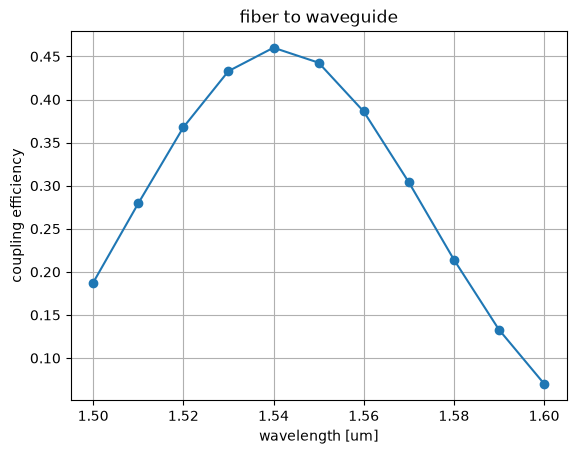

In [7]:
sol = lumi.load(path)
fiber_mode = np.array(sol["monitors"]["fiber"]["modes"][0]["-"])
wg_mode = np.array(sol["monitors"]["wg"]["modes"][0]["+"])
S = np.abs(wg_mode / fiber_mode) ** 2
print(f"params={params}, efficiency={S[nwls // 2]:.4f} at {wavelength} um")

plt.plot(wavelengths, S, "o-")
plt.xlabel("wavelength [um]")
plt.ylabel("coupling efficiency")
plt.title("fiber to waveguide")
plt.grid(True)
plt.show()

## Movie

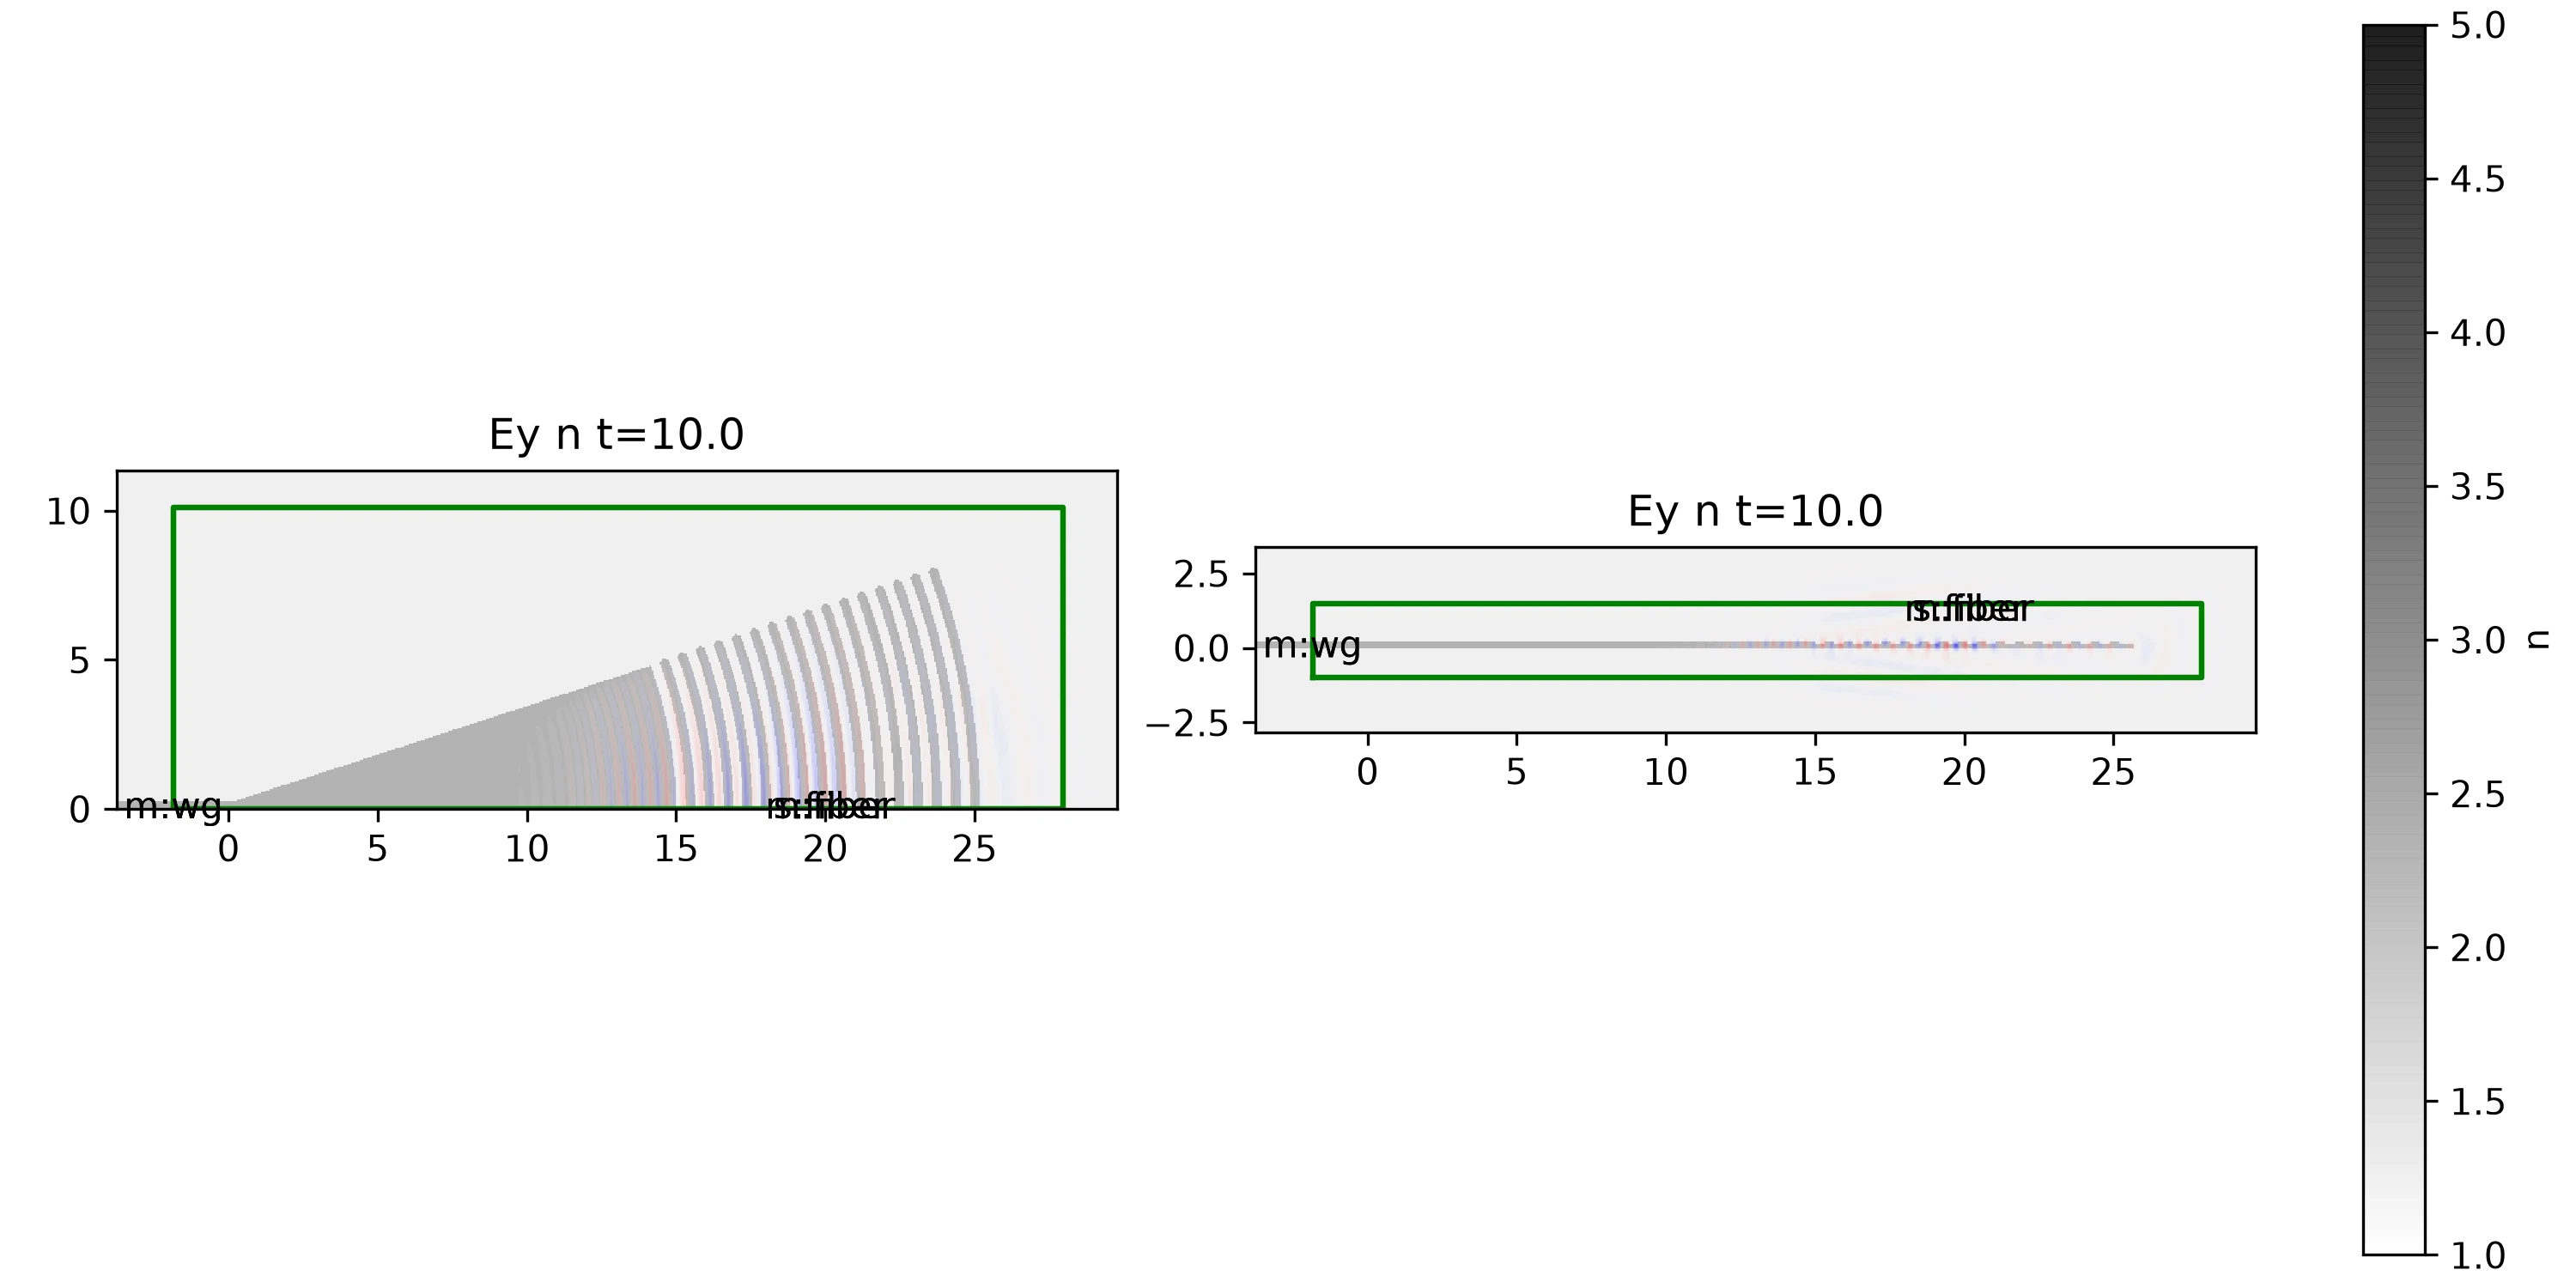

In [8]:
lumi.movie(path)
